# Stortingsvalg – landsresultater

Oppslutning, mandater og valgdeltakelse ved stortingsvalgene fra 2009. Kilde: Valgdirektoratet, [valgresultat.no](https://valgresultat.no).

Notebooken leser faktatabellene i `data/facts/`. Kjør `python run_scripts.py` fra prosjektroten først. De samme visningene finnes interaktivt i Streamlit-appen (`streamlit run src/app/streamlit_app.py`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path.cwd().parent / 'app'))
import election_data as ed

results = ed.load_results()
counting = ed.load_counting()
years = sorted(results['year'].unique())
year, previous_year = years[-1], years[-2]

INK, MUTED, GRID = '#31333f', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 10,
    'text.color': INK,
    'axes.labelcolor': MUTED,
    'axes.edgecolor': GRID,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': GRID,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'legend.frameon': False,
})

## Nøkkeltall

In [2]:
blocks = ed.mandates_by_block(results)
pd.DataFrame({
    'Valgdeltakelse': counting['turnout_percentage'].map(ed.fmt_pct).values,
    'Godkjente stemmer': counting['total_votes'].map(ed.fmt_int).values,
    'Andel forhåndsstemmer': counting['advance_share'].map(ed.fmt_pct).values,
    'Blanke stemmer': counting['blank_votes'].map(lambda v: '' if pd.isna(v) else ed.fmt_int(v)).values,
    'Mandater rødgrønne': blocks.loc[counting['year'], 'Rødgrønne'].values,
    'Mandater borgerlige': blocks.loc[counting['year'], 'Borgerlige'].values,
}, index=counting['year'].rename('Valg'))

,Valgdeltakelse,Godkjente stemmer,Andel forhåndsstemmer,Blanke stemmer,Mandater rødgrønne,Mandater borgerlige
Valg,,,,,,
2009,"76,0 %",2 682 903,"24,4 %",,86,83
2013,"78,2 %",2 848 903,"30,2 %",12 874,73,96
2017,"78,2 %",2 945 352,"36,3 %",18 516,81,88
2021,"77,2 %",3 003 290,"57,9 %",19 103,100,68
2025,"80,0 %",3 246 318,"62,9 %",26 430,88,81


## Resultat for siste valg

Oppslutning per parti, og endring i prosentpoeng fra valget før. Partier utenfor Stortinget er slått sammen til «Andre».

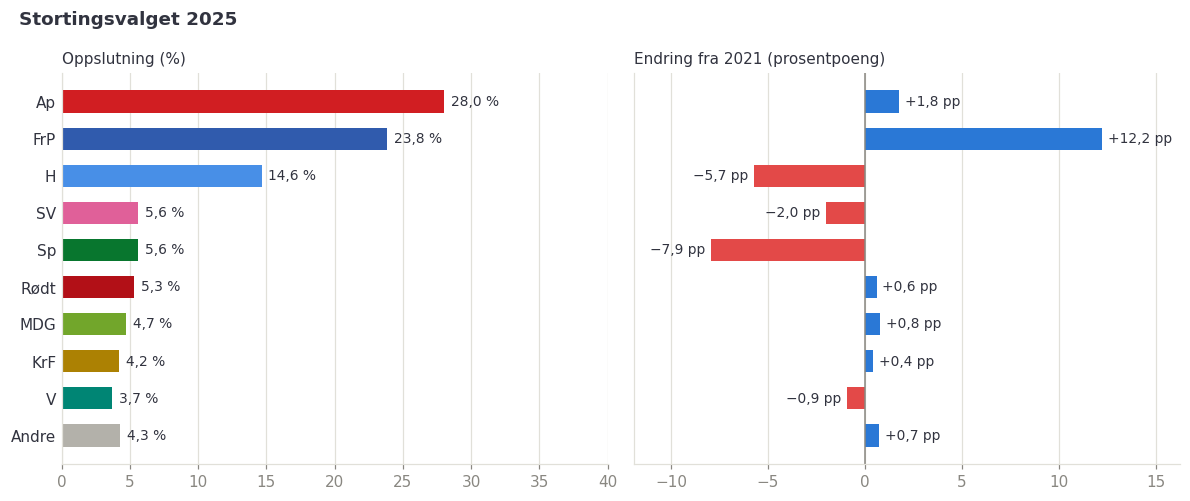

In [3]:
year_df = results[results['year'] == year]
main = year_df[year_df['party'] != ed.OTHER['label']].sort_values('votes_percentage')
year_df = pd.concat([year_df[year_df['party'] == ed.OTHER['label']], main])  # bottom to top

fig, (share_ax, change_ax) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
fig.suptitle(f'Stortingsvalget {year}', x=0.02, ha='left', fontweight='bold')

share_ax.barh(year_df['party'], year_df['votes_percentage'], height=0.6, color=year_df['color'])
for party, share in zip(year_df['party'], year_df['votes_percentage']):
    share_ax.text(share + 0.5, party, ed.fmt_pct(share), va='center', fontsize=9)
share_ax.set_xlim(0, 40)
share_ax.set_title('Oppslutning (%)', loc='left', fontsize=10, color=INK)
share_ax.grid(axis='y', visible=False)
share_ax.tick_params(axis='y', length=0, labelsize=10, labelcolor=INK)

colors = [ed.GAIN_COLOR if c >= 0 else ed.LOSS_COLOR for c in year_df['change']]
change_ax.barh(year_df['party'], year_df['change'], height=0.6, color=colors)
for party, change in zip(year_df['party'], year_df['change']):
    change_ax.text(change + (0.3 if change >= 0 else -0.3), party, ed.fmt_pp(change),
                   va='center', ha='left' if change >= 0 else 'right', fontsize=9)
change_ax.axvline(0, color=MUTED, linewidth=1)
low, high = min(year_df['change'].min(), 0) - 4, max(year_df['change'].max(), 0) + 4
change_ax.set_xlim(low, high)
change_ax.set_title(f'Endring fra {previous_year} (prosentpoeng)', loc='left', fontsize=10, color=INK)
change_ax.grid(axis='y', visible=False)
change_ax.tick_params(axis='y', length=0)

fig.tight_layout()
plt.show()

## Mandater

Partiene er ordnet fra venstre til høyre. Streken markerer flertall (85 av 169). MDG regnes her til rødgrønn side.

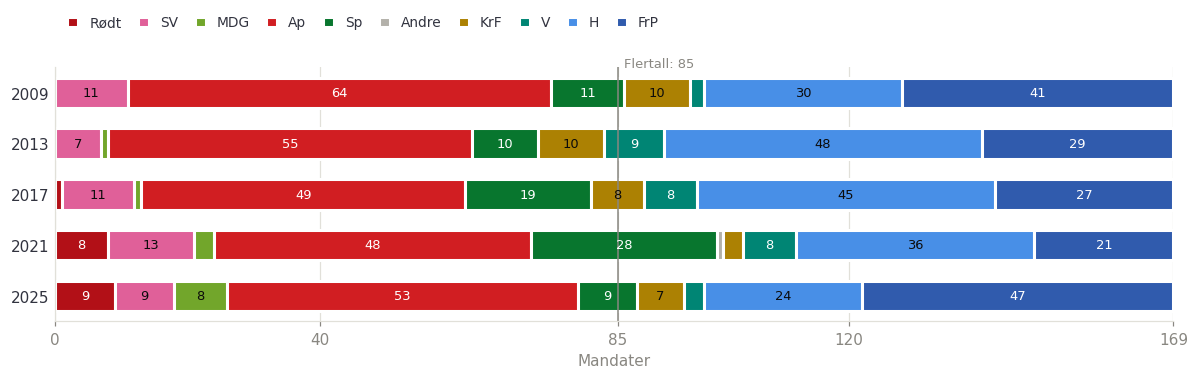

In [4]:
seats = results[results['mandates'] > 0].sort_values(['year', 'order']).copy()
seats['start'] = seats.groupby('year')['mandates'].cumsum() - seats['mandates']
# Numeric row positions, so every party lands on the right election even when it has no mandates in some years
seats['row'] = seats['year'].map({y: i for i, y in enumerate(years)})

fig, ax = plt.subplots(figsize=(11, 3.6))
for party in ed.PARTY_ORDER:
    rows = seats[seats['party'] == party]
    if rows.empty:
        continue
    # A white edge gives the gap between neighbouring segments
    ax.barh(rows['row'], rows['mandates'], left=rows['start'], height=0.6,
            color=ed.PARTY_COLORS[party], edgecolor='white', linewidth=2, label=party)
    for _, row in rows[rows['mandates'] >= 5].iterrows():
        ax.text(row['start'] + row['mandates'] / 2, row['row'], row['mandates'],
                ha='center', va='center', fontsize=8.5, color=ed.text_color_on(row['color']))

ax.axvline(ed.MAJORITY, color=MUTED, linewidth=1)
ax.text(ed.MAJORITY + 1, -0.45, f'Flertall: {ed.MAJORITY}', color=MUTED, fontsize=8.5, va='bottom')
ax.set(xlim=(0, 169), xticks=[0, 40, 85, 120, 169], xlabel='Mandater')
ax.set_yticks(range(len(years)), [str(y) for y in years])
ax.set_ylim(len(years) - 0.5, -0.5)  # first election at the top
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.legend(ncol=len(ed.PARTY_ORDER), loc='lower left', bbox_to_anchor=(0, 1.1), handlelength=0.8,
          columnspacing=1.2, fontsize=9)
fig.tight_layout()
plt.show()

## Oppslutning over tid

Hvert parti er uthevet mot de andre partiene i grått.

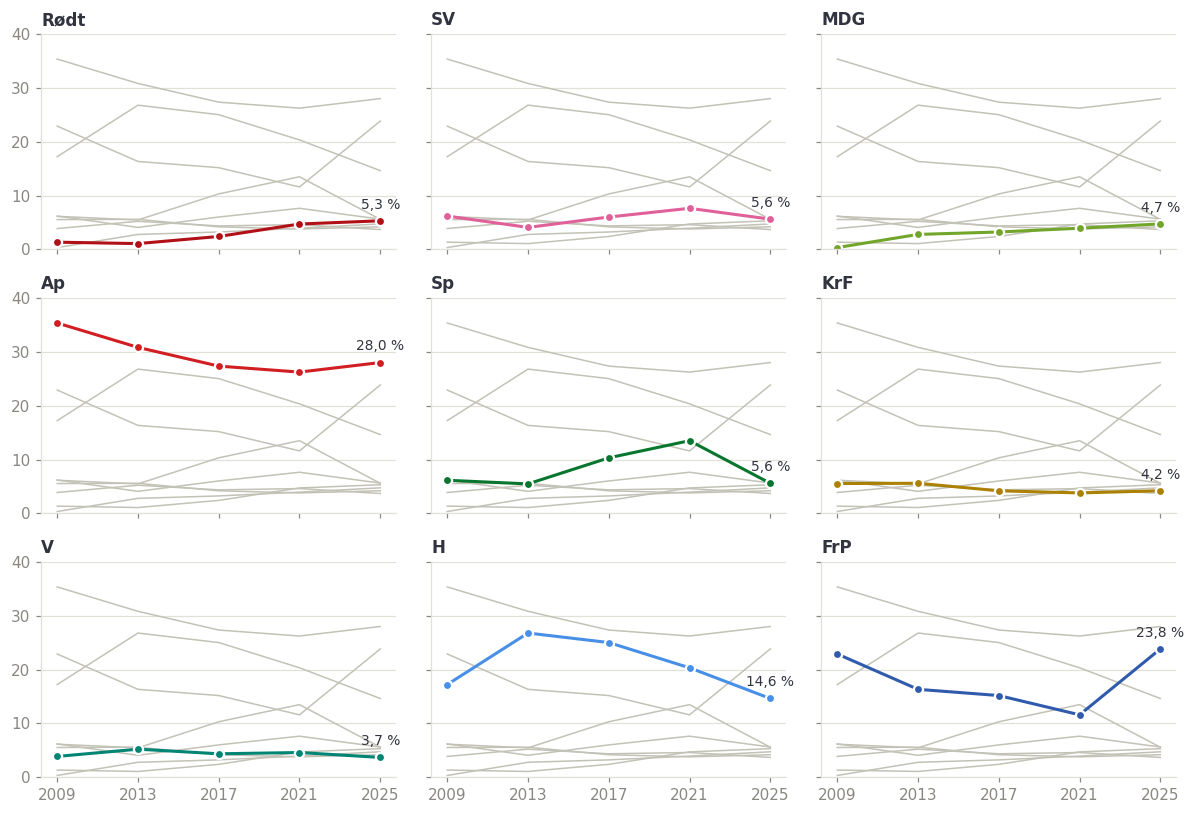

In [5]:
parties = [p for p in ed.PARTY_ORDER if p != ed.OTHER['label']]
shares = results.pivot(index='year', columns='party', values='votes_percentage')

fig, axes = plt.subplots(3, 3, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, party in zip(axes.flat, parties):
    for other in parties:
        if other != party:
            ax.plot(shares.index, shares[other], color='#c3c2b7', linewidth=1)
    ax.plot(shares.index, shares[party], color=ed.PARTY_COLORS[party], linewidth=2,
            marker='o', markersize=6, markeredgecolor='white', markeredgewidth=1.5)
    ax.annotate(ed.fmt_pct(shares.loc[year, party]), (year, shares.loc[year, party]),
                textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
    ax.set_title(party, loc='left', fontsize=11, fontweight='bold', color=INK)
    ax.set(ylim=(0, 40), xticks=years)
    ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

## Valgdeltakelse og forhåndsstemmer

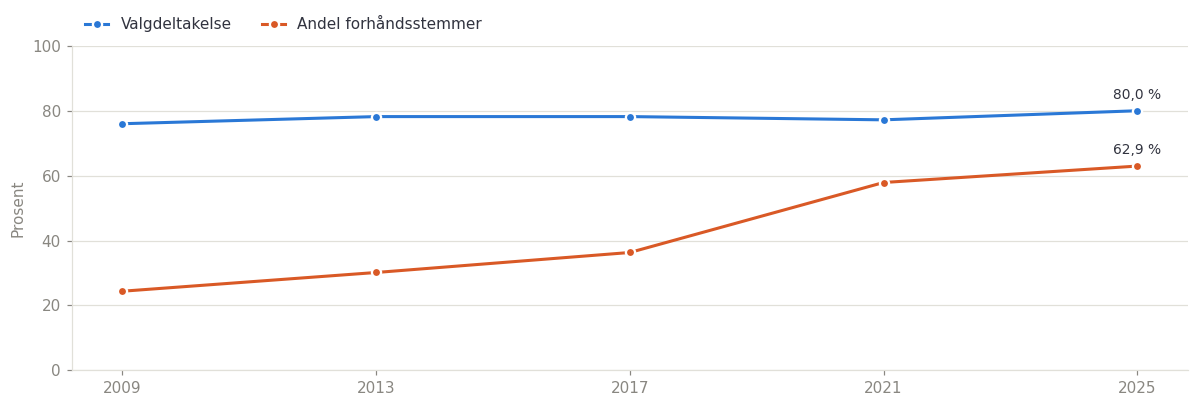

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for column, label, color in [('turnout_percentage', 'Valgdeltakelse', ed.TURNOUT_COLOR),
                             ('advance_share', 'Andel forhåndsstemmer', ed.ADVANCE_COLOR)]:
    ax.plot(counting['year'], counting[column], color=color, linewidth=2, label=label,
            marker='o', markersize=6, markeredgecolor='white', markeredgewidth=1.5)
    ax.annotate(ed.fmt_pct(counting[column].iloc[-1]), (year, counting[column].iloc[-1]),
                textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
ax.set(ylim=(0, 100), xticks=years, ylabel='Prosent')
ax.grid(axis='x', visible=False)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, handlelength=1.5)
fig.tight_layout()
plt.show()